# KNN (k-nearest neighbors)
---

* Algoritmo de los k vecinos más cercanos (próximos)
* Permite realizar **clasificación supervisada** (se conoce la clase objetivo, ejemplo: mamifero, no mamifero)
* Conocer la "etiqueta" (valor declarado para cada caso) en el conjunto de entrenamiento
* Es un método no paramétrico, no construye un modelo. Es simplemente aplicar un algoritmo
* Método simple y efectivo, competitivo con algoritmos más complejos

## ¿Cómo clasifica?

* Ejemplo con 2 predictores
* Se tiene un conjunto de casos ya clasificados (conjunto de entrenamiento)
* Se quiere clasificar un caso nuevo (c/u de los casos de testing, por cada uno calcula las distancias a todos)
* Si se toma **K=3**, se considera los 3 casos más cercanos (medida de distancia)
* Hay 2 /\ y 1 (), entonces clasifica como /\

![KNN](img/knn.png)

* Tomo como base los casos de entrenamiento donde conozco la clase "y"
* Caso 1 de test: ejemplo cercanos dos 0 y un 1 => clasifica 0 con prob 2/3 = 0.66
* Caso 2 de test: ejemplo cercanos tres 0 => clasifica 0 con prob 3/3 = 1.0

## Observaciones

* Se requiere elegir k previamente (cuantos vecinos voy a considerar)! Se sugiere k impar para evitar empates
* Hay que decidir la distancia a considerar. Lo usual es la euclídea pero permite Manhattan, Minkowsk ...
* Las variables deben ser todas numéricas, aunque pueden usarse categóricas convertidas a numéricas ficticiamente (dummies)
* Se recomienda normalizar o estandarizar las variables numéricas previamente

## Pros y Contras

| PROS                                                  | CONTRAS                                                   |
| --                                                    | --                                                        |
| No hace suposiciones de distribución de las variables | Requiere datos completos                                  |
| No "aprende" un modelo, es sólo un algoritmo          | Es sensible al ruido: ver outliers (para no ser tironeado |
| No le afecta multicolinealidad                        | Con muchas predictoras, costoso computacionalmente        |
|                                                       | K grande da resultados más estables, pero mayor costo     |

## Ejemplo Hipoteca

In [3]:
library(ggplot2)
library(readxl)
library(dplyr)
library(caret) 
library(ROCR)
library(class)
library(fastDummies)
library(ISLR)

In [4]:
setwd("/Users/ppando/Materias/cs-datos/especializacion/data")

In [5]:
datos <- read_excel("hipoteca25.xlsx")
str(datos)

tibble [2,380 × 8] (S3: tbl_df/tbl/data.frame)
 $ id       : num [1:2380] 1 2 3 4 5 6 7 8 9 10 ...
 $ gasto    : num [1:2380] 0.221 0.265 0.372 0.32 0.36 ...
 $ rat      : num [1:2380] 0.8 0.922 0.92 0.86 0.6 ...
 $ rat.desem: num [1:2380] 3.9 3.2 3.2 4.3 3.2 ...
 $ malhist  : chr [1:2380] "no" "no" "no" "no" ...
 $ auton    : chr [1:2380] "no" "no" "no" "no" ...
 $ soltero  : chr [1:2380] "no" "yes" "no" "no" ...
 $ denegado : num [1:2380] 0 0 0 0 0 0 0 0 1 0 ...


In [6]:
# Se elimina id
datos <- datos[, -1]

In [7]:
# Se transforma las variables cualitativas a factor
datos$denegado <- as.factor(datos$denegado)
datos$soltero <- as.factor(datos$soltero)
datos$auton <- as.factor(datos$auton)
datos$malhist <- as.factor(datos$malhist)

In [8]:
# Se muestra el summary
summary(datos)

     gasto             rat              rat.desem     malhist    auton     
 Min.   :0.0000   Min.   :0.000e+00   Min.   :0.000   no :2205   no :2103  
 1st Qu.:0.2800   1st Qu.:1.000e+00   1st Qu.:3.100   yes: 175   yes: 277  
 Median :0.3300   Median :1.000e+00   Median :3.200                        
 Mean   :0.3308   Mean   :8.600e+11   Mean   :3.013                        
 3rd Qu.:0.3700   3rd Qu.:1.000e+00   3rd Qu.:3.600                        
 Max.   :3.0000   Max.   :1.908e+14   Max.   :8.900                        
 soltero    denegado
 no :1444   0:2095  
 yes: 936   1: 285  
                    
                    
                    
                    

In [9]:
#sum(is.na(datos)) #no hay faltantes
datos2 <- datos[datos$rat < 1.5,] # o imputar!!!
summary(datos2)

     gasto             rat           rat.desem     malhist    auton     
 Min.   :0.0000   Min.   :0.0200   Min.   :0.000   no :2182   no :2085  
 1st Qu.:0.2800   1st Qu.:0.6513   1st Qu.:3.100   yes: 172   yes: 269  
 Median :0.3300   Median :0.7778   Median :3.200                        
 Mean   :0.3297   Mean   :0.7324   Mean   :3.014                        
 3rd Qu.:0.3700   3rd Qu.:0.8639   3rd Qu.:3.600                        
 Max.   :3.0000   Max.   :1.2000   Max.   :8.900                        
 soltero    denegado
 no :1432   0:2082  
 yes: 922   1: 272  
                    
                    
                    
                    

In [10]:
View(datos2)

gasto,rat,rat.desem,malhist,auton,soltero,denegado
<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>
0.221,0.8000000,3.90,no,no,no,0
0.265,0.9218750,3.20,no,no,yes,0
0.372,0.9203980,3.20,no,no,no,0
0.320,0.8604651,4.30,no,no,no,0
0.360,0.6000000,3.20,no,no,no,0
0.240,0.5105263,3.90,no,no,no,0
0.350,0.7466667,3.90,no,no,yes,0
0.280,0.8500000,1.80,no,no,no,0
0.310,0.8972603,3.10,no,no,no,1


In [11]:
# vamos a usar sólo las numéricas como predictoras
datos3 <- select(datos2, c("gasto", "rat", "rat.desem", "denegado"))
summary(datos3)

     gasto             rat           rat.desem     denegado
 Min.   :0.0000   Min.   :0.0200   Min.   :0.000   0:2082  
 1st Qu.:0.2800   1st Qu.:0.6513   1st Qu.:3.100   1: 272  
 Median :0.3300   Median :0.7778   Median :3.200           
 Mean   :0.3297   Mean   :0.7324   Mean   :3.014           
 3rd Qu.:0.3700   3rd Qu.:0.8639   3rd Qu.:3.600           
 Max.   :3.0000   Max.   :1.2000   Max.   :8.900           

In [12]:
# Conj de entrenamiento (se conoce la etiqueta) y se lo evalua en conj de testing
set.seed(123)
# indices <- sample(1:nrow(datos), nrow(datos) * 0.70, replace=FALSE)
indices <- createDataPartition(datos3$denegado, p=0.7, list=FALSE)
dataTrain <- datos3[indices, ]
dataTest <- datos3[-indices, ]
summary(dataTest)

     gasto             rat           rat.desem     denegado
 Min.   :0.0400   Min.   :0.0200   Min.   :0.000   0:624   
 1st Qu.:0.2800   1st Qu.:0.6438   1st Qu.:3.100   1: 81   
 Median :0.3359   Median :0.7783   Median :3.200           
 Mean   :0.3271   Mean   :0.7320   Mean   :3.012           
 3rd Qu.:0.3714   3rd Qu.:0.8678   3rd Qu.:3.600           
 Max.   :0.9500   Max.   :1.2000   Max.   :8.900           

In [13]:
# Se clasifica en test con knn 
cuantis.knn <- knn(train = select(dataTrain, !denegado), # la parte de predictores (las x´s) en entrenamiento
                   test = select(dataTest, !denegado),   # la parte de predictores (las x´s) en testing
                   cl = dataTrain$denegado,              # clase real en entrenamiento
                   k = 3,                                # cuantos vecinos cercanos se va a considerar
                   prob = T)                             # para que calcule una probabilidad
head(cuantis.knn, 10)                                    # en que clasifican los primeros 10 casos

[1] 0 0 0 0 0 1 0 0 0 0
Levels: 0 1

In [14]:
# Se puede pedir la probabilidad con que clasifica a la clase correspondiente
# prob = (#casos de la clase mas votada)/k
prob1 <- attr(cuantis.knn, "prob")
head(prob1, 10)
# OJO! no confundir con la probabilidad de clasificar como positivo!
# Prob 1 significa que los tres vecninos cercanos tenian la misma clase con la cual se clasifico

[1] 1.0000000 1.0000000 1.0000000 1.0000000 1.0000000 0.6666667 1.0000000
 [8] 1.0000000 1.0000000 1.0000000

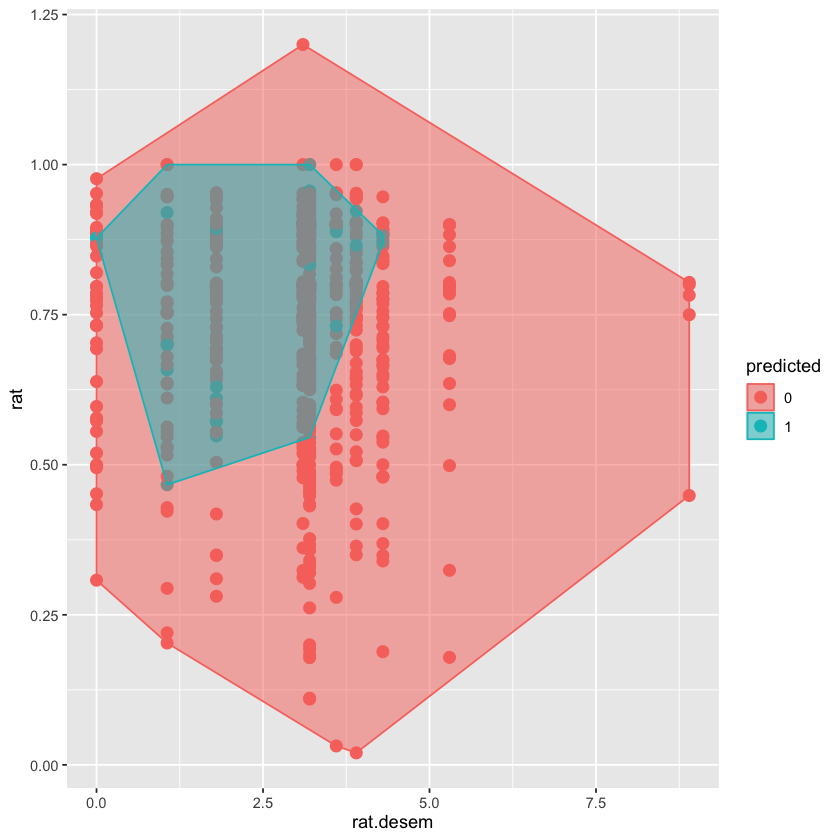

In [15]:
#Veamos en un gráfico de 2 predictores:
plot.df <- dataTest %>% select(rat.desem,rat) %>% mutate(predicted = as.factor(cuantis.knn))
plot.df1 <- data.frame(x = plot.df$rat.desem, 
                       y = plot.df$rat, 
                       predicted = plot.df$predicted)

find_hull <- function(df) df[chull(df$x, df$y), ]
boundary <- plyr::ddply(plot.df1, .variables = "predicted", .fun = find_hull)

ggplot(plot.df1, aes(x, y, color = predicted, fill = predicted)) + 
  geom_point(size = 3) + 
  geom_polygon(data = boundary, aes(x,y), alpha = 0.5) + 
  xlab("rat.desem") + 
  ylab("rat")

* Sirve para mirar la clasificación de los nuevos (no sirve mucho)

In [16]:
# Para evaluar la clasificación: métricas confusión y curva ROC (para Knn no se usa curva ROC)
confusion1 <- table(predict = cuantis.knn, Actual = dataTest$denegado)
confusionMatrix(confusion1, positive = "1")

Confusion Matrix and Statistics

       Actual
predict   0   1
      0 600  72
      1  24   9
                                          
               Accuracy : 0.8638          
                 95% CI : (0.8363, 0.8883)
    No Information Rate : 0.8851          
    P-Value [Acc > NIR] : 0.9639          
                                          
                  Kappa : 0.0979          
                                          
 Mcnemar's Test P-Value : 1.611e-06       
                                          
            Sensitivity : 0.11111         
            Specificity : 0.96154         
         Pos Pred Value : 0.27273         
         Neg Pred Value : 0.89286         
             Prevalence : 0.11489         
         Detection Rate : 0.01277         
   Detection Prevalence : 0.04681         
      Balanced Accuracy : 0.53632         
                                          
       'Positive' Class : 1               
                                          

* Accuracy bueno 
* Sensitividad mala
* Clasifica bien a los 0, y mal a los 1

## Ejemplo con variables categóricas (cualitativas)

In [17]:
## Para convertir factores (yes/no) en dummies por ej soltero_yes con valor 0 ó 1
datos2.dummies <- dummy_cols(datos2, 
                             select_columns = c("soltero", "auton", "malhist"), # variables categóricas a transformar en 0 ó 1
                             remove_selected_columns = T,                       # elimina las originales dejando solo las dummies
                             remove_first_dummy = T)
View(datos2.dummies)

# podría usar esta base con variables escaladas...

gasto,rat,rat.desem,denegado,soltero_yes,auton_yes,malhist_yes
<dbl>,<dbl>,<dbl>,<fct>,<int>,<int>,<int>
0.221,0.8000000,3.90,0,0,0,0
0.265,0.9218750,3.20,0,1,0,0
0.372,0.9203980,3.20,0,0,0,0
0.320,0.8604651,4.30,0,0,0,0
0.360,0.6000000,3.20,0,0,0,0
0.240,0.5105263,3.90,0,0,0,0
0.350,0.7466667,3.90,0,1,0,0
0.280,0.8500000,1.80,0,0,0,0
0.310,0.8972603,3.10,1,0,0,0


## Ejemplo Smarket

In [18]:
data(Smarket)
mercados <- Smarket # porcentajes diarios de rendimiento para el índice bursátil S&P 500 entre el 2001 y 2005
head(mercados)
summary(mercados)
str(mercados)       # ver que la variable objetivo esté como factor

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,2001,0.381,-0.192,-2.624,-1.055,5.010,1.1913,0.959,Up
2,2001,0.959,0.381,-0.192,-2.624,-1.055,1.2965,1.032,Up
3,2001,1.032,0.959,0.381,-0.192,-2.624,1.4112,-0.623,Down
4,2001,-0.623,1.032,0.959,0.381,-0.192,1.2760,0.614,Up
5,2001,0.614,-0.623,1.032,0.959,0.381,1.2057,0.213,Up
6,2001,0.213,0.614,-0.623,1.032,0.959,1.3491,1.392,Up


      Year           Lag1                Lag2                Lag3          
 Min.   :2001   Min.   :-4.922000   Min.   :-4.922000   Min.   :-4.922000  
 1st Qu.:2002   1st Qu.:-0.639500   1st Qu.:-0.639500   1st Qu.:-0.640000  
 Median :2003   Median : 0.039000   Median : 0.039000   Median : 0.038500  
 Mean   :2003   Mean   : 0.003834   Mean   : 0.003919   Mean   : 0.001716  
 3rd Qu.:2004   3rd Qu.: 0.596750   3rd Qu.: 0.596750   3rd Qu.: 0.596750  
 Max.   :2005   Max.   : 5.733000   Max.   : 5.733000   Max.   : 5.733000  
      Lag4                Lag5              Volume           Today          
 Min.   :-4.922000   Min.   :-4.92200   Min.   :0.3561   Min.   :-4.922000  
 1st Qu.:-0.640000   1st Qu.:-0.64000   1st Qu.:1.2574   1st Qu.:-0.639500  
 Median : 0.038500   Median : 0.03850   Median :1.4229   Median : 0.038500  
 Mean   : 0.001636   Mean   : 0.00561   Mean   :1.4783   Mean   : 0.003138  
 3rd Qu.: 0.596750   3rd Qu.: 0.59700   3rd Qu.:1.6417   3rd Qu.: 0.596750  
 Max. 

'data.frame':	1250 obs. of  9 variables:
 $ Year     : num  2001 2001 2001 2001 2001 ...
 $ Lag1     : num  0.381 0.959 1.032 -0.623 0.614 ...
 $ Lag2     : num  -0.192 0.381 0.959 1.032 -0.623 ...
 $ Lag3     : num  -2.624 -0.192 0.381 0.959 1.032 ...
 $ Lag4     : num  -1.055 -2.624 -0.192 0.381 0.959 ...
 $ Lag5     : num  5.01 -1.055 -2.624 -0.192 0.381 ...
 $ Volume   : num  1.19 1.3 1.41 1.28 1.21 ...
 $ Today    : num  0.959 1.032 -0.623 0.614 0.213 ...
 $ Direction: Factor w/ 2 levels "Down","Up": 2 2 1 2 2 2 1 2 2 2 ...


In [19]:
# Se crea entrenamiento y test
set.seed(123)
index <- createDataPartition(y = mercados$Direction, p = 0.75, list = FALSE)
entreno <- mercados[index, ]
testeo <- mercados[-index, ]

* Se va a usar "train" de caret para buscar un k adecuado en conj de entrenamiento 
1. buscando k en una grilla de valores impares 
2. estandarizar (centrar y escalar) las predictoras
3. calcular accuracy en entreno por cross validation 

In [20]:
# Puedo definir una grilla de parámetros a probar
# Se busca un K
valores <- expand.grid(k = seq(15, 35, 2)) 
set.seed(123)
knnEntrenado <- train(Direction ~ ., 
                      data = entreno, 
                      method = "knn",  
                      #tuneLength = 20,   # opcion para decir #valores de k que le pido que pruebe
                      tuneGrid = valores, # opcion para decir la grilla a recorrer
                      trControl = trainControl(method = "cv", number = 5) ,
                      preProcess = c("center", "scale"))
knnEntrenado

k-Nearest Neighbors 

938 samples
  8 predictor
  2 classes: 'Down', 'Up' 

Pre-processing: centered (8), scaled (8) 
Resampling: Cross-Validated (5 fold) 
Summary of sample sizes: 750, 751, 750, 751, 750 
Resampling results across tuning parameters:

  k   Accuracy   Kappa    
  15  0.8592388  0.7169978
  17  0.8613835  0.7210027
  19  0.8666913  0.7316772
  21  0.8677779  0.7339944
  23  0.8773694  0.7531850
  25  0.8752247  0.7487059
  27  0.8837467  0.7659764
  29  0.8730857  0.7445117
  31  0.8762999  0.7509707
  33  0.8773751  0.7530866
  35  0.8805780  0.7596306

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was k = 27.

* Para cada k de la grilla
    * Para cada caso  
        * Agarro un caso y lo clasifico según las otras partes del conjunto training
        * Luego comparo con lo real y saco accuracy
* Se queda con k que maximiza Accuracy (o sea, mínimo error)

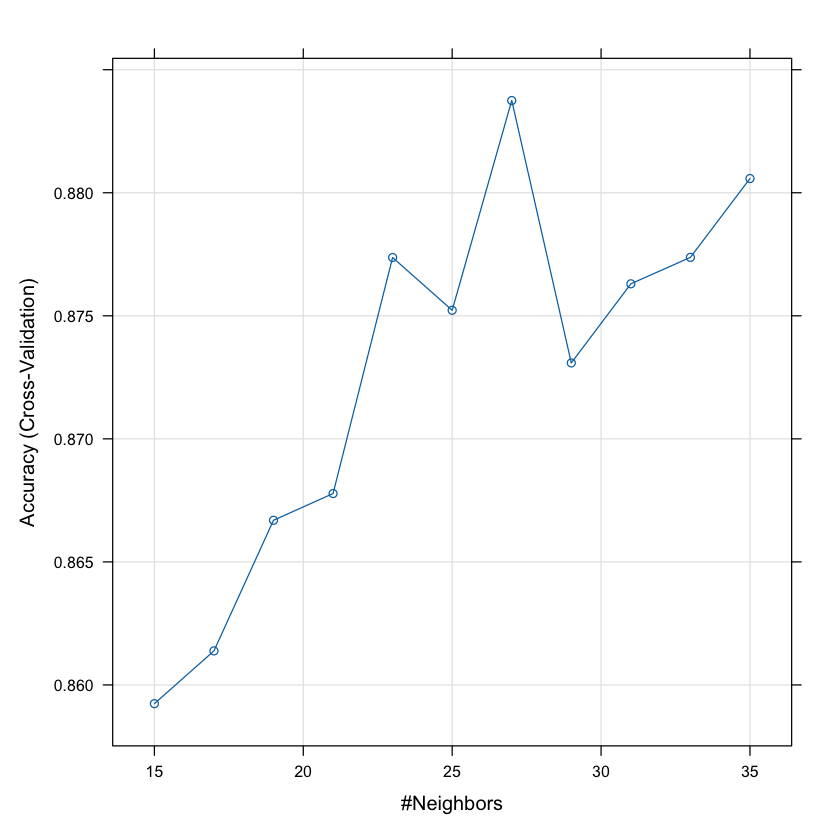

In [21]:
plot(knnEntrenado)

In [22]:
names(knnEntrenado)      # knnEntrenado es un objeto
knnEntrenado$metric      # la métrica que usó para evaluar el mejor k
knnEntrenado$bestTune    # el mejor k
knnEntrenado$finalModel

[1] "method"       "modelInfo"    "modelType"    "results"      "pred"        
 [6] "bestTune"     "call"         "dots"         "metric"       "control"     
[11] "finalModel"   "preProcess"   "trainingData" "ptype"        "resample"    
[16] "resampledCM"  "perfNames"    "maximize"     "yLimits"      "times"       
[21] "levels"       "terms"        "coefnames"    "xlevels"

[1] "Accuracy"

,k
,<dbl>
7,27


27-nearest neighbor model
Training set outcome distribution:

Down   Up 
 452  486 


In [23]:
summary(entreno$Direction)

Down   Up 
 452  486

In [24]:
## La prediccion en test:
knnPrediccion <- predict(knnEntrenado, newdata = testeo )
head(knnPrediccion)      # muestra como clasificaron los 6 primeros casos 
prob_knnPrediccion <- predict(knnEntrenado, newdata = testeo , type = "prob")
head(prob_knnPrediccion) # ver que da las probabilidades de cada clase

[1] Up   Down Down Up   Up   Down
Levels: Down Up

,Down,Up
,<dbl>,<dbl>
1,0.3333333,0.6666667
2,0.7037037,0.2962963
3,0.7407407,0.2592593
4,0.4444444,0.5555556
5,0.1111111,0.8888889
6,0.7037037,0.2962963


In [25]:
# Métricas
confusionMatrix(knnPrediccion, testeo$Direction, positive = "Up")

Confusion Matrix and Statistics

          Reference
Prediction Down  Up
      Down  129   4
      Up     21 158
                                         
               Accuracy : 0.9199         
                 95% CI : (0.884, 0.9475)
    No Information Rate : 0.5192         
    P-Value [Acc > NIR] : < 2.2e-16      
                                         
                  Kappa : 0.8388         
                                         
 Mcnemar's Test P-Value : 0.001374       
                                         
            Sensitivity : 0.9753         
            Specificity : 0.8600         
         Pos Pred Value : 0.8827         
         Neg Pred Value : 0.9699         
             Prevalence : 0.5192         
         Detection Rate : 0.5064         
   Detection Prevalence : 0.5737         
      Balanced Accuracy : 0.9177         
                                         
       'Positive' Class : Up             
                                         

* Accuracy, Sensitivity, Specificity dan todos muy bien (Es un caso de libro)

[1] 0.6666667 0.2962963 0.2592593 0.5555556 0.8888889 0.2962963

[[1]]
[1] 0.982428

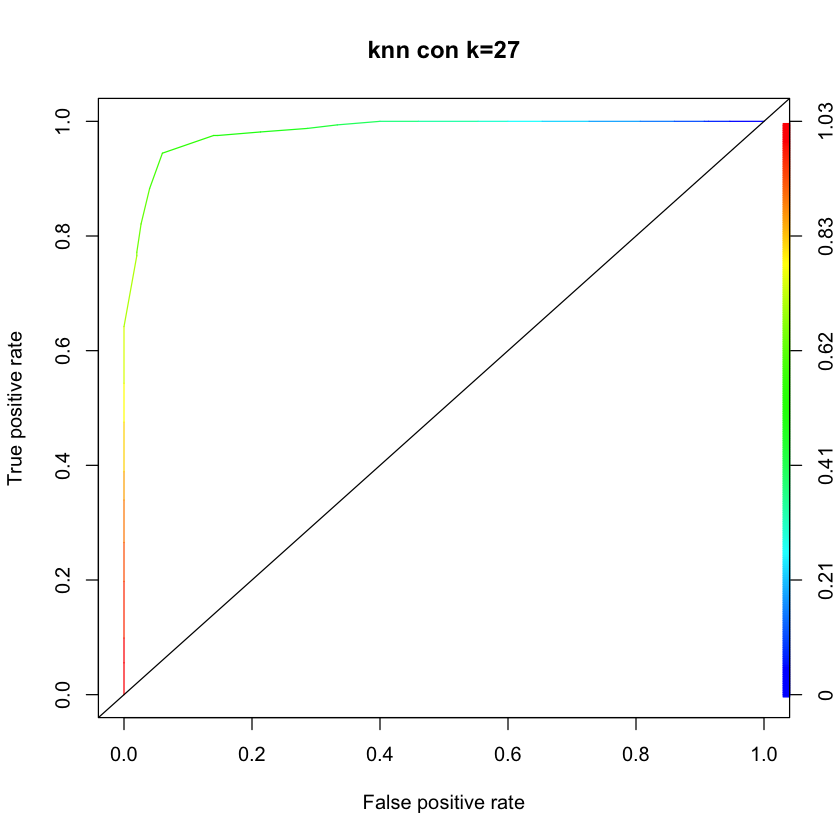

In [26]:
# ROC y AUC: no es muy usado como métricas en knn !!!
# Probabilidades de "Up" (clase positiva) para el cálculo de la curva ROC:

knn_prob_UP <- prob_knnPrediccion[,2]
head(knn_prob_UP)
 
prediccion_knn <- prediction(knn_prob_UP, testeo$Direction)
roc_knn <- performance(prediccion_knn, measure = "tpr", x.measure = "fpr")

plot(roc_knn, main = "knn con k=27", colorize = T)
abline(a = 0, b = 1)
AUC.knn <- performance(prediccion_knn, "auc")@y.values
AUC.knn